# ML Assignment 2 - QSAR Biodegradation

**Machine Learning | BITS WILP M.Tech (AIML)**

In this notebook I check the QSAR Biodegradation dataset and test Logistic Regression as the first classifier. The same train/test split will be used for the remaining models.

Dataset: [UCI QSAR Biodegradation](https://archive.ics.uci.edu/dataset/254/qsar%2Bbiodegradation) (41 input features, 1 binary target). I use `RB` (ready biodegradable) as the positive class.

## 1. Imports

In [16]:
import sys
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('numpy:', np.__version__)
print('joblib:', joblib.__version__)

Python: 3.12.7
pandas: 2.2.3
scikit-learn: 1.9.1
numpy: 2.5.4
joblib: 1.4.2


## 2. Read the dataset

The file is semicolon-separated and does not contain a header. If downloading is blocked, upload `biodeg.csv` to the notebook folder.

In [18]:
possible_paths = [
    Path('biodeg.csv'),
    Path('data/biodeg.csv'),
    Path('../data/biodeg.csv'),
]
raw_path = next((p for p in possible_paths if p.is_file()), None)

if raw_path is None:
    dataset_url = 'https://archive.ics.uci.edu/static/public/254/qsar%2Bbiodegradation.zip'
    try:
        with urlopen(dataset_url, timeout=30) as response:
            zipped_bytes = response.read()
        with ZipFile(BytesIO(zipped_bytes)) as archive:
            filename = next(
                name for name in archive.namelist()
                if name.rsplit('/', 1)[-1] == 'biodeg.csv'
            )
            raw_path = Path('biodeg.csv')
            raw_path.write_bytes(archive.read(filename))
        print('Downloaded original dataset to:', raw_path)
    except Exception as exc:
        raise RuntimeError(
            'Could not download the dataset. Download from the UCI page, '
            'extract biodeg.csv, upload it beside this notebook, and rerun.'
        ) from exc
else:
    print('Using local data file:', raw_path)

raw = pd.read_csv(raw_path, sep=';', header=None, skipinitialspace=True)
print('Raw shape (rows, all columns):', raw.shape)
display(raw.head(3))

Downloaded original dataset to: biodeg.csv
Raw shape (rows, all columns): (1055, 42)


,0,1,2,3,4,5,6,7,8,9,...,32,33,34,35,36,37,38,39,40,41
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,...,0,0,0,2.949,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,...,0,0,0,3.315,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,...,0,0,1,3.076,2.417,0,7.601,0,0,RB


## 3. Data checks

In [20]:
assert raw.shape[1] == 42, f'Expected 42 columns, found {raw.shape[1]}'

feature_columns = [f'feature_{i:02d}' for i in range(1, 42)]
df = raw.copy()
df.columns = feature_columns + ['target']

df['target'] = df['target'].astype('string').str.strip()
for name in feature_columns:
    df[name] = pd.to_numeric(df[name], errors='raise')

assert set(df['target'].dropna().unique()) == {'NRB', 'RB'}, 'Unexpected class labels'
assert len(df) >= 500 and len(feature_columns) >= 12, 'Assignment size conditions not met'
assert not df.isna().any().any(), 'Found missing values; investigate before modeling'

print('Rows:', len(df))
print('Input features:', len(feature_columns))
print('Missing cells:', int(df.isna().sum().sum()))
print('Identical complete rows:', int(df.duplicated().sum()))
print('Identical feature rows:', int(df.duplicated(subset=feature_columns).sum()))
print('\nTarget counts:')
display(df['target'].value_counts().rename_axis('class').to_frame('records'))

display(df[feature_columns].describe().T.head(8))

Rows: 1055
Input features: 41
Missing cells: 0
Identical complete rows: 3
Identical feature rows: 3

Target counts:


,records
class,
NRB,699
RB,356


,count,mean,std,min,25%,50%,75%,max
feature_01,1055.0,4.782644,0.546916,2.0000,4.48100,4.8280,5.12500,6.4960
feature_02,1055.0,3.069508,0.831308,0.8039,2.50275,3.0463,3.43765,9.1775
feature_03,1055.0,0.716588,1.462452,0.0000,0.00000,0.0000,1.00000,12.0000
feature_04,1055.0,0.042654,0.256010,0.0000,0.00000,0.0000,0.00000,3.0000
feature_05,1055.0,0.980095,2.332955,0.0000,0.00000,0.0000,1.00000,36.0000
feature_06,1055.0,0.290047,1.073771,0.0000,0.00000,0.0000,0.00000,13.0000
feature_07,1055.0,1.646445,2.224822,0.0000,0.00000,1.0000,3.00000,18.0000
feature_08,1055.0,37.055640,9.144466,0.0000,30.45000,37.5000,43.40000,60.7000


### Class distribution

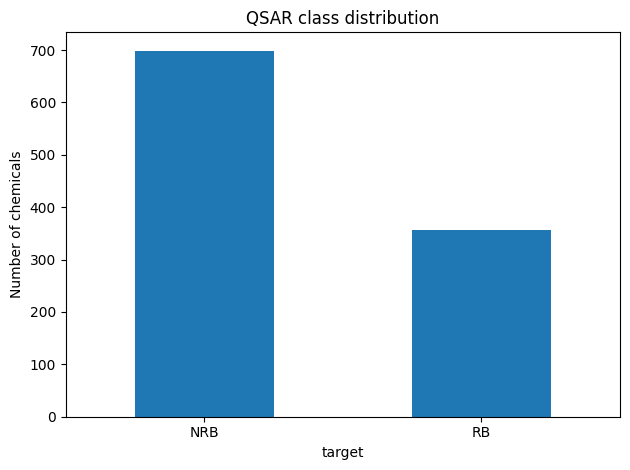

Majority-class-only guess: NRB; accuracy: 0.663


In [22]:
class_counts = df['target'].value_counts()
class_counts.plot(kind='bar', title='QSAR class distribution', ylabel='Number of chemicals', rot=0)
plt.tight_layout()
plt.show()

majority_class = class_counts.idxmax()
majority_accuracy = class_counts.max() / len(df)
print(f'Majority-class-only guess: {majority_class}; accuracy: {majority_accuracy:.3f}')

## 4. Train/test split

80% training data and 20% test data, stratified by target.

In [24]:
X = df[feature_columns]
y = df['target'].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print('Training records:', len(X_train))
print('Test records:', len(X_test))
print('Train class share (%)')
print((y_train.value_counts(normalize=True) * 100).round(1))
print('Test class share (%)')
print((y_test.value_counts(normalize=True) * 100).round(1))

train_signatures = set(map(tuple, X_train.to_numpy()))
test_signatures = set(map(tuple, X_test.to_numpy()))
overlap_count = len(train_signatures.intersection(test_signatures))
print('Unique exact feature rows shared across train and test:', overlap_count)
if overlap_count:
    print('WARNING: Inspect duplicate features and reconsider the split before final reporting.')

Training records: 844
Test records: 211
Train class share (%)
target
NRB    66.2
RB     33.8
Name: proportion, dtype: float64
Test class share (%)
target
NRB    66.4
RB     33.6
Name: proportion, dtype: float64
Unique exact feature rows shared across train and test: 0


## 5. Logistic Regression

I used a pipeline so that scaling is fitted only on training data.

In [26]:
logistic_model = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42)),
])

logistic_model.fit(X_train, y_train)
print('Pipeline trained on', len(X_train), 'training rows.')
print('Target class order:', logistic_model.classes_.tolist())

Pipeline trained on 844 training rows.
Target class order: ['NRB', 'RB']


## 6. Evaluation

For precision, recall and F1 the positive class is `RB`. AUC uses predicted probabilities.

In [28]:
positive_label = 'RB'
y_pred = logistic_model.predict(X_test)
rb_column = list(logistic_model.classes_).index(positive_label)
rb_probability = logistic_model.predict_proba(X_test)[:, rb_column]

metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'AUC': roc_auc_score((y_test == positive_label).astype(int), rb_probability),
    'Precision': precision_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
    'Recall': recall_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
    'F1': f1_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
    'MCC': matthews_corrcoef(y_test, y_pred),
}

baseline_table = pd.DataFrame([{'Model': 'Logistic Regression', **metrics}])
display(baseline_table.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8626,0.9136,0.8,0.7887,0.7943,0.6912


## 7. Confusion matrix

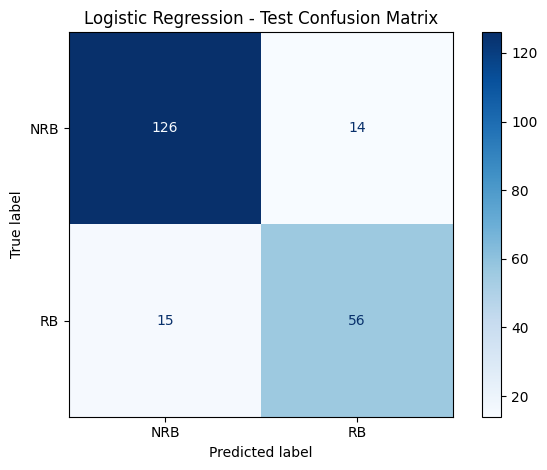

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=['NRB', 'RB'],
    display_labels=['NRB', 'RB'],
    cmap='Blues',
    values_format='d',
)
plt.title('Logistic Regression - Test Confusion Matrix')
plt.tight_layout()
plt.show()

## 8. Save the model and test data

The model file includes the scaler, so it can be reused in Streamlit without refitting.

In [32]:
output_root = Path.cwd()
model_dir = output_root / 'model'
model_dir.mkdir(parents=True, exist_ok=True)

saved_test_data = X_test.copy()
saved_test_data['target'] = y_test
saved_test_data.to_csv(output_root / 'test_data.csv', index=False)

joblib.dump(logistic_model, model_dir / 'logistic_regression.joblib')
baseline_table.to_csv(output_root / 'baseline_metrics.csv', index=False)

print('Saved:', (output_root / 'test_data.csv').resolve())
print('Saved:', (model_dir / 'logistic_regression.joblib').resolve())
print('Saved:', (output_root / 'baseline_metrics.csv').resolve())
print('Test CSV shape:', pd.read_csv(output_root / 'test_data.csv').shape)

Saved: /home/s2026aj05843/workspace/ML Assignment 2/test_data.csv
Saved: /home/s2026aj05843/workspace/ML Assignment 2/model/logistic_regression.joblib
Saved: /home/s2026aj05843/workspace/ML Assignment 2/baseline_metrics.csv
Test CSV shape: (211, 42)


## 9. Observations

The notes below are calculated from the results produced when this notebook runs. They refer to the Logistic Regression baseline only; I will compare all five classifiers after training the remaining four.

In [34]:
from IPython.display import Markdown, display
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=['NRB', 'RB'])
tn, fp, fn, tp = cm.ravel()
missing = int(df.isna().sum().sum())
repeated = int(df.duplicated().sum())
majority_count = int(class_counts.max())
minority_count = int(class_counts.min())

if fn > fp:
    error_note = f'More ready-biodegradable cases were missed (FN={fn}) than non-ready cases incorrectly marked ready (FP={fp}).'
elif fp > fn:
    error_note = f'More non-ready cases were incorrectly marked ready (FP={fp}) than ready cases missed (FN={fn}).'
else:
    error_note = f'The two error types were equally frequent (FP={fp}, FN={fn}).'

if metrics['Accuracy'] > majority_accuracy:
    accuracy_note = 'The test accuracy is higher than the majority-class baseline from the full dataset.'
elif metrics['Accuracy'] < majority_accuracy:
    accuracy_note = 'The test accuracy is lower than the majority-class baseline from the full dataset.'
else:
    accuracy_note = 'The test accuracy equals the majority-class baseline from the full dataset.'

observations = f'''### Logistic Regression - results

- **Dataset:** {len(df)} samples and {len(feature_columns)} numeric input features. I found {missing} missing values and {repeated} duplicate complete rows.
- **Class balance:** {majority_class} is the majority class ({majority_count} rows versus {minority_count}). This makes accuracy alone an incomplete performance measure.
- **Test set:** {len(y_test)} rows, separate from the {len(y_train)} training rows.
- **Metrics:** Accuracy = {metrics['Accuracy']:.3f}, AUC = {metrics['AUC']:.3f}, Precision = {metrics['Precision']:.3f}, Recall = {metrics['Recall']:.3f}, F1 = {metrics['F1']:.3f}, MCC = {metrics['MCC']:.3f}.
- **Accuracy check:** {accuracy_note}
- **Confusion matrix:** Correct NRB = {tn}, correct RB = {tp}, false positives = {fp}, false negatives = {fn}. {error_note}
- **Next:** Compare Decision Tree, KNN, Gaussian Naive Bayes and SVM on this same split before selecting the best model.
'''
display(Markdown(observations))


### Logistic Regression - results

- **Dataset:** 1055 samples and 41 numeric input features. I found 0 missing values and 3 duplicate complete rows.
- **Class balance:** NRB is the majority class (699 rows versus 356). This makes accuracy alone an incomplete performance measure.
- **Test set:** 211 rows, separate from the 844 training rows.
- **Metrics:** Accuracy = 0.863, AUC = 0.914, Precision = 0.800, Recall = 0.789, F1 = 0.794, MCC = 0.691.
- **Accuracy check:** The test accuracy is higher than the majority-class baseline from the full dataset.
- **Confusion matrix:** Correct NRB = 126, correct RB = 56, false positives = 14, false negatives = 15. More ready-biodegradable cases were missed (FN=15) than non-ready cases incorrectly marked ready (FP=14).
- **Next:** Compare Decision Tree, KNN, Gaussian Naive Bayes and SVM on this same split before selecting the best model.
